# Jaccard similarity

Overlap between the *esame* (exam) and *ansia* (anxiety) semantic frames of each whole sample, human and
GPT-oss, built on the 17 cue words shared by every cue set. The frame of a word is its set of neighbours
in the group's BFMN, and the overlap is the Jaccard index of the two neighbour sets.

Each sample is compared with its GPT-oss counterpart by a participant-level permutation test. The
Jaccard index is one value per group, computed on the pooled network, so tests that need a sample of
values per group (t-test, Mann-Whitney) do not apply. Instead, the students and personas of a sample are
pooled, reassigned at random to two groups of the original sizes, and both networks are rebuilt; the
p-value is the share of permuted differences at least as large as the observed one. The test makes no
distributional assumption, and the matched design keeps the two groups the same size. The three
samples are tested separately, with Holm's correction for the three tests.


In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

from config import RESSERENO_ROOT, COMMON_CUES_RASSERENO
from bfmn_building import text_cleaning, build_association_df
from jaccard_similarity_bfmn import jaccard_similarity, get_sets_of_associations

path_rassereno_analysis = RESSERENO_ROOT / "out" / "analysis"
SPLITS = RESSERENO_ROOT / "out" / "splitted_dfs"

N_PERM = 10000
rng = np.random.default_rng(2026)

## Groups

Export key in `all_bfmns.pkl` -> split file it was built from.


In [2]:
SPLIT_FOLDERS = {
    "high_school": "high_school_2025",
    "physics": "physics_2025",
    "psychology": "psychology_exam_anx_paper",
    "gpt_oss_high_school": "high_school_gpt_oss",
    "gpt_oss_physics": "physics_gpt_oss",
    "gpt_oss_psychology": "psychology_gpt_oss",
}
# whole samples only (no anxiety split)
GROUPS = {f"{name}_all": f"{folder}/all.csv" for name, folder in SPLIT_FOLDERS.items()}

with open(path_rassereno_analysis / "all_bfmns.pkl", "rb") as f:
    features = pickle.load(f)

## Participant-level neighbour sets

In the BFMN every cue is linked to each of its associations, so the neighbours of *esame* contributed
by one participant are the words they gave to *esame* plus the cues to which they answered *esame*.
The group's neighbour set is the union over its participants.


In [3]:
def participant_neighbours(split_df, w1="esame", w2="ansia"):
    """List of (neighbours of w1, neighbours of w2), one pair per participant."""
    split_df = split_df[split_df["cue_word"].isin(COMMON_CUES_RASSERENO)]
    long_df = build_association_df(text_cleaning(split_df))
    long_df = long_df[long_df["cue_word"] != long_df["word"]]
    pairs = []
    for _, p in long_df.groupby("participant_id"):
        sets = []
        for w in (w1, w2):
            sets.append(
                set(p.loc[p["cue_word"] == w, "word"])
                | set(p.loc[p["word"] == w, "cue_word"])
            )
        pairs.append(tuple(sets))
    return pairs


def pooled_jaccard(pairs, idx=None):
    idx = range(len(pairs)) if idx is None else idx
    n1, n2 = set(), set()
    for i in idx:
        n1 |= pairs[i][0]
        n2 |= pairs[i][1]
    return jaccard_similarity(n1, n2) if n1 | n2 else 0.0


neighbours = {
    g: participant_neighbours(pd.read_csv(SPLITS / f)) for g, f in GROUPS.items()
}

## Observed values

`J_frames` is computed from the exported frames (`all_bfmns.pkl`) as a check: it must equal `J`.


In [4]:
rows = []
for g, pairs in neighbours.items():
    anxiety_words, _, exam_words = get_sets_of_associations(features[g])
    rows.append(
        {
            "group": g,
            "N": len(pairs),
            "J": pooled_jaccard(pairs),
            "J_frames": jaccard_similarity(exam_words, anxiety_words),
        }
    )
jaccard = pd.DataFrame(rows).set_index("group")
assert np.allclose(jaccard["J"], jaccard["J_frames"])
jaccard = jaccard.drop(columns="J_frames")
jaccard.round(3)

,N,J
group,,
high_school_all,96,0.110
physics_all,24,0.081
psychology_all,189,0.097
gpt_oss_high_school_all,96,0.066
gpt_oss_physics_all,24,0.062
gpt_oss_psychology_all,189,0.085


## Humans vs GPT-oss

For each sample: observed difference (humans minus GPT-oss), ratio, two-sided permutation p-value and
Holm-adjusted p-value across the three samples. The exported table marks the differences significant
at alpha = 0.1 (Holm-adjusted) with `*`; the p-values are kept in a separate file.


In [5]:
def compare(a, b, n_perm=N_PERM):
    pooled = neighbours[a] + neighbours[b]
    n_a = len(neighbours[a])
    observed = jaccard.loc[a, "J"] - jaccard.loc[b, "J"]
    null = np.empty(n_perm)
    for i in range(n_perm):
        order = rng.permutation(len(pooled))
        null[i] = pooled_jaccard(pooled, order[:n_a]) - pooled_jaccard(
            pooled, order[n_a:]
        )
    return {
        "J_humans": jaccard.loc[a, "J"],
        "J_gpt_oss": jaccard.loc[b, "J"],
        "diff": observed,
        "ratio": jaccard.loc[a, "J"] / jaccard.loc[b, "J"],
        "p": (np.sum(np.abs(null) >= abs(observed)) + 1) / (n_perm + 1),
    }


def holm(p_values):
    """Holm-Bonferroni adjusted p-values."""
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p_values[i]))
        adjusted[i] = running
    return adjusted


HUMAN_SAMPLES = ["high_school", "physics", "psychology"]
comparisons = pd.DataFrame(
    {s: compare(f"{s}_all", f"gpt_oss_{s}_all") for s in HUMAN_SAMPLES}
).T
comparisons["p_holm"] = holm(comparisons["p"].to_numpy())
comparisons.index.name = "sample"

ALPHA = 0.1
table = comparisons[["J_humans", "J_gpt_oss", "diff", "ratio"]].astype(float).round(3)
table["diff"] = table["diff"].map("{:.3f}".format) + np.where(
    comparisons["p_holm"] < ALPHA, "*", ""
)
table

,J_humans,J_gpt_oss,diff,ratio
sample,,,,
high_school,0.110,0.066,0.044*,1.658
physics,0.081,0.062,0.020,1.319
psychology,0.097,0.085,0.012,1.147


## Plot

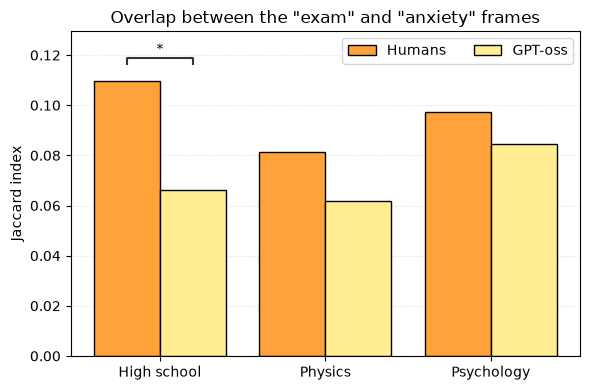

In [6]:
LABELS = {
    "high_school": "High school",
    "physics": "Physics",
    "psychology": "Psychology",
}
plot_df = pd.DataFrame(
    [
        {
            "sample": LABELS[s],
            "source": source,
            "J": jaccard.loc[f"{prefix}{s}_all", "J"],
        }
        for s in HUMAN_SAMPLES
        for prefix, source in [("", "Humans"), ("gpt_oss_", "GPT-oss")]
    ]
)
order = [LABELS[s] for s in HUMAN_SAMPLES]
hue_order = ["Humans", "GPT-oss"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    data=plot_df,
    x="sample",
    y="J",
    hue="source",
    order=order,
    hue_order=hue_order,
    palette={"Humans": "#FFA239", "GPT-oss": "#FEEE91"},
    saturation=1,
    edgecolor="black",
    ax=ax,
)

# significance brackets from the Holm-adjusted permutation p-values computed above
pairs = [((LABELS[s], "Humans"), (LABELS[s], "GPT-oss")) for s in HUMAN_SAMPLES]
annotator = Annotator(
    ax,
    pairs,
    data=plot_df,
    x="sample",
    y="J",
    hue="source",
    order=order,
    hue_order=hue_order,
)
annotator.configure(
    text_format="star",
    pvalue_thresholds=[[ALPHA, "*"], [1, "ns"]],
    alpha=ALPHA,
    hide_non_significant=True,
    loc="inside",
    verbose=0,
)
annotator.set_pvalues([comparisons.loc[s, "p_holm"] for s in HUMAN_SAMPLES])
annotator.annotate()

ax.set_xlabel("")
ax.set_ylabel("Jaccard index")
ax.set_title('Overlap between the "exam" and "anxiety" frames')
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(
    title_fontsize=8,
    loc="upper right",
    ncol=2,
)
fig.tight_layout()
(path_rassereno_analysis / "comparison_plots").mkdir(exist_ok=True)
fig.savefig(
    path_rassereno_analysis / "comparison_plots" / "exam_anxiety_comp.pdf", dpi=300
)